# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Henry Saputra
- **Email:** henrysaputra007@gmail.com
- **ID Dicoding:** hytra_46

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Berapa persentase pertumbuhan jumlah sewa sepeda, pengguna terdaftar (registered), dan pengguna casual dari tahun 2011 ke 2012?
- **Pertanyaan 2:** Pada hari kerja (*working days*) tahun 2012, pada jam berapa rata-rata jumlah penyewaan sepeda mulai meningkat dibandingkan jam sebelumnya?

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Data Wrangling

### Gathering Data

#### Load day_df

In [3]:
# Memuat dataset day.csv ke dalam variabel day_df
day_df = pd.read_csv("/content/drive/MyDrive/Dicoding Submission: Proyek Analisis Data/data/day.csv")

# Melihat 5 baris pertama day_df
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


#### Load hour_df

In [4]:
# Memuat dataset day.csv ke dalam variabel hour_df
hour_df = pd.read_csv("/content/drive/MyDrive/Dicoding Submission: Proyek Analisis Data/data/hour.csv")

# Melihat 5 baris pertama hour_df
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Kita telah berhasil memuat semua data yang dibutuhkan.
- Ada dua dataset yang dimuat kedalam variabel, yaitu: day_df dan hour_df.

### Assessing Data

#### Identifying day_df problem

In [5]:
# Memeriksa tipe data dari tiap kolom dan kelengkapan data.
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [6]:
# Memeriksa jumlah missing values data tiap kolom.
day_df.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


In [7]:
# Memeriksa duplikasi data.
print("Jumlah duplikasi: ", day_df.duplicated().sum())

Jumlah duplikasi:  0


In [8]:
# Memeriksa parameter statistik dari kolom numerik.
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


#### Identifying hour_df problem

In [9]:
# Memeriksa tipe data dari tiap kolom dan kelengkapan data.
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [10]:
# Memeriksa jumlah missing values data tiap kolom.
hour_df.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


In [11]:
# Memeriksa duplikasi data.
print("Jumlah duplikasi: ", hour_df.duplicated().sum())

Jumlah duplikasi:  0


In [12]:
# Memeriksa parameter statistik dari kolom numerik.
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Steps to Take:**
- Identifikasi tipe data
- Identifikasi missing value
- Identifikasi duplicate data
- Identifikasi Statistik deskriptif data

**Insight:** (Opsional)
- Dataset tidak memiliki missing value dan duplicated data.
- Terdapat kesalahan tipe data untuk kolom dteday. Kolom tersebut harusnya direpresentasikan sebagai tipe data datetime, bukan object.

### Cleaning Data

#### Fixing 'Kesalahan Tipe Data' problem

In [13]:
# Mengganti tipe data pada kolom dteday menjadi datetime.
day_df["dteday"] = pd.to_datetime(day_df["dteday"])

# Memeriksa tipe data dari tiap kolom dan kelengkapan data.
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[ns]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[ns](1), floa

In [14]:
# Mengganti tipe data pada kolom dteday menjadi datetime.
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

# Memeriksa tipe data dari tiap kolom dan kelengkapan data.
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[ns]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-

**Insight:** (Opsional)
- Kesalahan tipe data pada kolom dteday berhasil diperbaiki.

## Exploratory Data Analysis (EDA)

### Explore Pertanyaan 1: Berapa persentase pertumbuhan jumlah sewa sepeda, pengguna terdaftar (registered), dan pengguna casual dari tahun 2011 ke 2012?

In [15]:
# Mengcopy day_df ke pertahun_df
pertahun_df = day_df.copy()

# Mengubah kolom dteday menjadi tahun
pertahun_df["yr"] = pertahun_df["dteday"].dt.year

# Mengelompokkan data berdasarkan tahun
pertahun_df.groupby(by="yr").agg({
    "cnt": "sum",
    "registered": "sum",
    "casual": "sum"
})

,cnt,registered,casual
yr,,,
2011,1243103,995851,247252
2012,2049576,1676811,372765


In [16]:
# Menghitung persentase kenaikan cnt registered casual dari tahun 2011 ke 2012
cnt_2011 = pertahun_df[pertahun_df['yr'] == 2011]['cnt'].sum()
cnt_2012 = pertahun_df[pertahun_df['yr'] == 2012]['cnt'].sum()
registered_2011 = day_df[day_df['yr'] == 0]['registered'].sum()
registered_2012 = day_df[day_df['yr'] == 1]['registered'].sum()
casual_2011 = day_df[day_df['yr'] == 0]['casual'].sum()
casual_2012 = day_df[day_df['yr'] == 1]['casual'].sum()

persentase_kenaikan_cnt = ((cnt_2012 - cnt_2011) / cnt_2011) * 100
persentase_kenaikan_registered = ((registered_2012 - registered_2011) / registered_2011) * 100
persentase_kenaikan_casual = ((casual_2012 - casual_2011) / casual_2011) * 100

print(f"Persentase kenaikan cnt: {persentase_kenaikan_cnt:.2f}%")
print(f"Persentase kenaikan registered: {persentase_kenaikan_registered:.2f}%")
print(f"Persentase kenaikan casual: {persentase_kenaikan_casual:.2f}%")

Persentase kenaikan cnt: 64.88%
Persentase kenaikan registered: 68.38%
Persentase kenaikan casual: 50.76%


### Explore Pertanyaan 2: Pada hari kerja (*working days*) tahun 2012, pada jam berapa rata-rata jumlah penyewaan sepeda mulai meningkat dibandingkan jam sebelumnya?

In [27]:
# Menyalin hour_df ke workingday_2012_df
workingday_2012_df = hour_df.copy()

# Memfilter data tahun 2012, bukan hari libur, dan hari kerja
workingday_2012_df = workingday_2012_df[
    (workingday_2012_df["yr"] == 1) &
    (workingday_2012_df["holiday"] == 0) &
    (workingday_2012_df["workingday"] == 1)
]

# Menampilkan hasil filter
workingday_2012_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
8692,8693,2012-01-03,1,1,1,0,0,2,1,1,0.20,0.1970,0.51,0.2537,0,13,13
8693,8694,2012-01-03,1,1,1,1,0,2,1,1,0.18,0.1818,0.55,0.2239,1,5,6
8694,8695,2012-01-03,1,1,1,2,0,2,1,1,0.18,0.1667,0.51,0.2537,0,3,3
8695,8696,2012-01-03,1,1,1,3,0,2,1,1,0.16,0.1364,0.55,0.2836,0,2,2
8696,8697,2012-01-03,1,1,1,4,0,2,1,1,0.16,0.1515,0.55,0.2537,0,5,5


In [28]:
# Mengelompokkan data berdasarkan hr dengan cnt agregat average
rata_sewa_per_jam_df = workingday_2012_df.groupby(
    by="hr"
).agg({
    "cnt": "mean"
}).reset_index()

# Mengurutkan data berdasarkan jam
rata_sewa_per_jam_df = rata_sewa_per_jam_df.sort_values(
    by="hr",
    ascending=True
)

# Menampilkan hasil agregasi
rata_sewa_per_jam_df

,hr,cnt
0,0,44.188755
1,1,19.358871
2,2,9.810484
3,3,5.489627
4,4,6.032653
5,5,32.000000
6,6,127.508065
7,7,366.548387
8,8,604.508065
9,9,302.391129


In [24]:
# Menambahkan kolom rata-rata penyewaan pada jam sebelumnya
rata_sewa_per_jam_df["cnt_sebelumnya"] = (
    rata_sewa_per_jam_df["cnt"].shift(1)
)

# Menghitung perubahan rata-rata penyewaan dibandingkan jam sebelumnya
rata_sewa_per_jam_df["perubahan_cnt"] = (
    rata_sewa_per_jam_df["cnt"] -
    rata_sewa_per_jam_df["cnt_sebelumnya"]
)

# Memfilter jam ketika rata-rata penyewaan meningkat
peningkatan_sewa_df = rata_sewa_per_jam_df[
    rata_sewa_per_jam_df["perubahan_cnt"] > 0
]

# Menampilkan hasil
peningkatan_sewa_df

,hr,cnt,cnt_sebelumnya,perubahan_cnt
4,4,6.032653,5.489627,0.543027
5,5,32.000000,6.032653,25.967347
6,6,127.508065,32.000000,95.508065
7,7,366.548387,127.508065,239.040323
8,8,604.508065,366.548387,237.959677
11,11,198.725806,169.310484,29.415323
12,12,253.612903,198.725806,54.887097
15,15,255.991968,229.775100,26.216867
16,16,371.542169,255.991968,115.550201
17,17,656.188755,371.542169,284.646586


**Insight:** (Opsional)
- xxx
- xxx

## Visualization & Explanatory Analysis

### Pertanyaan 1: Berapa persentase pertumbuhan jumlah sewa sepeda, pengguna terdaftar (registered), dan pengguna casual dari tahun 2011 ke 2012?

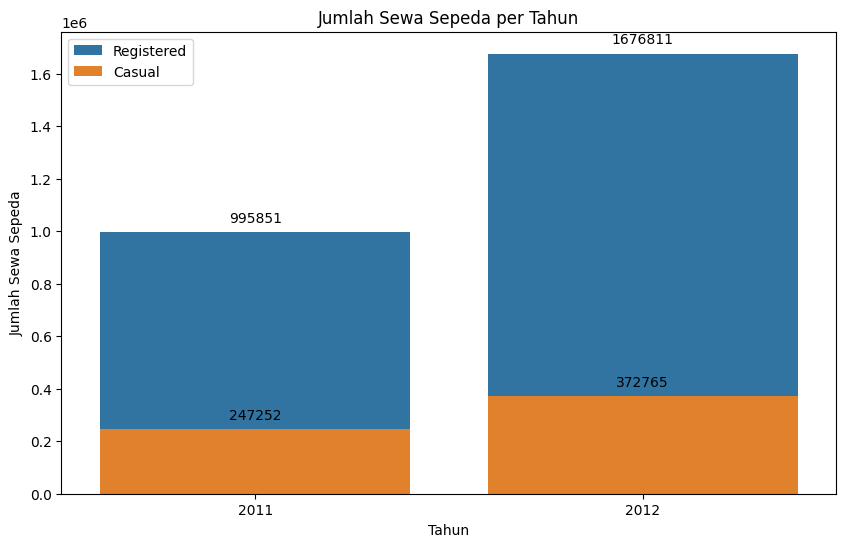

In [18]:
# Membuat dataframe baru untuk visualisasi
viz_df = pertahun_df.groupby(by="yr").agg({
    "registered": "sum",
    "casual": "sum"
}).reset_index()

# Membuat bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x="yr", y="registered", data=viz_df, label="Registered")
sns.barplot(x="yr", y="casual", data=viz_df, label="Casual")

# Menambahkan label jumlah di atas setiap bar
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                   ha='center', va='center', xytext=(0, 10), textcoords='offset points')

plt.xlabel("Tahun")
plt.ylabel("Jumlah Sewa Sepeda")
plt.title("Jumlah Sewa Sepeda per Tahun")
plt.legend()
plt.show()

### Pertanyaan 2: Pada hari kerja (*working days*) tahun 2012, pada jam berapa rata-rata jumlah penyewaan sepeda mulai meningkat dibandingkan jam sebelumnya?

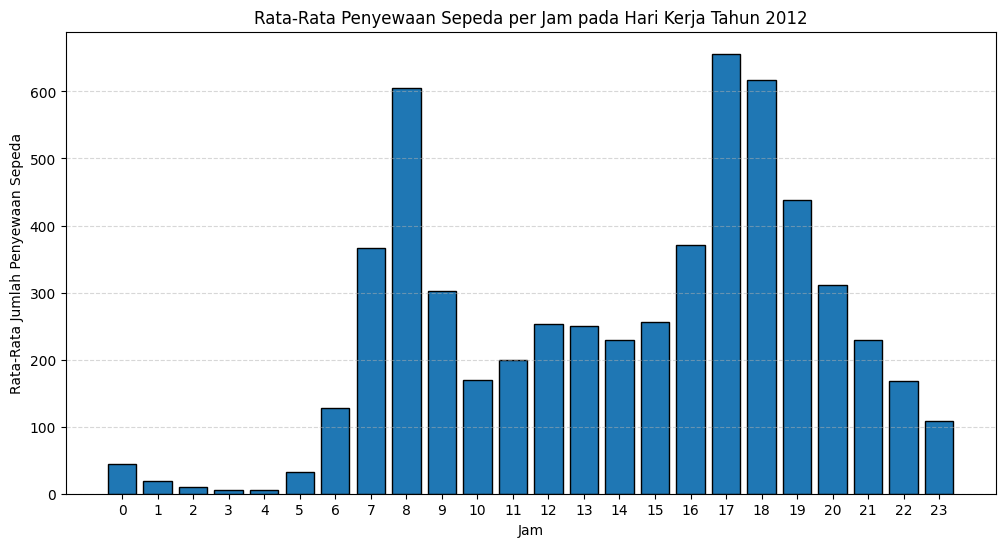

In [29]:
# Membuat bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    rata_sewa_per_jam_df["hr"],
    rata_sewa_per_jam_df["cnt"],
    edgecolor="black"
)

plt.title("Rata-Rata Penyewaan Sepeda per Jam pada Hari Kerja Tahun 2012")
plt.xlabel("Jam")
plt.ylabel("Rata-Rata Jumlah Penyewaan Sepeda")
plt.xticks(range(24))
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

**Insight:** (Opsional)
- xxx
- xxx

## Analisis Lanjutan (Opsional)

**Insight:** (Opsional)
- xxx
- xxx

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Terjadi kenaikan jumlah sewa sepeda dari tahun 2011 ke 2012.
Persentase kenaikan jumlah sewa sepeda keseluruhan: 64.88%, dengan
persentase kenaikan pengguna registered: 68.38% dan persentase kenaikan pengguna casual: 50.76%.
- **Conclusion pertanyaan 2:** Pada hari kerja tahun 2012, rata-rata jumlah penyewaan sepeda mulai meningkat pada pukul 05.00–08.00, dengan peningkatan paling signifikan terjadi pada pukul 07.00–08.00, dari 366,55 menjadi 604,51 penyewaan. Peningkatan kembali terlihat pada pukul 15.00–17.00, dengan puncak rata-rata penyewaan pada pukul 17.00 sebesar 656,19 penyewaan.


**Rekomendasi Action Item:**
- Rekomendasi Pertanyaan 1: Pengelola layanan sepeda disarankan untuk mempertahankan strategi yang berhasil meningkatkan jumlah penyewaan pada tahun 2012, terutama dengan meningkatkan promosi program keanggotaan dan memberikan insentif bagi pengguna casual agar beralih menjadi pengguna terdaftar. Hal ini dapat mendorong pertumbuhan jumlah penyewa secara berkelanjutan.
- Rekomendasi Pertanyaan 2: Pengelola layanan sepeda disarankan untuk memastikan ketersediaan sepeda pada jam sibuk, terutama pukul 07.00–08.00 dan 16.00–18.00, guna mengantisipasi peningkatan permintaan. Selain itu, distribusi sepeda perlu dioptimalkan pada jam-jam tersebut agar kebutuhan pengguna dapat terpenuhi dengan baik.